# 2 · Check one sample end to end — and verify the explanation

This is the **real-life workflow** in a notebook:

1. take one memory sample (a row of 55 forensics features),
2. get the classifier's verdict and probability,
3. get the SHAP evidence behind it,
4. get a natural-language explanation,
5. **verify that the explanation is faithful** to the evidence — and watch the
   checker catch explanations that lie.

No LLM and no API key are needed: step 4 uses the deterministic template, and step 5
is pure Python. At the end we show how to swap in a real model (Ollama, an
OpenAI-compatible endpoint, or the agent queue) and how to call the same thing from
the shell with `python -m src.cli`.

Run from the repository root, after `make setup download preprocess train evidence`.


In [1]:
# Make the project importable no matter where Jupyter was started from.
import os, sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "utils" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
print("repo root:", ROOT)


repo root: /home/faddy/Desktop/githubrepos/ransomware-rationale


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
%matplotlib inline

from src.evidence.build_evidence import build_one, load_glossary
from src.evidence.shap_builder import compute_shap
from src.faithfulness.extract_rules import extract_claims, infer_verdict_and_probability
from src.faithfulness.verify import score_rationale
from src.generation.prompts import render_evidence_table
from src.generation.template_baseline import template_rationale
from src.models.calibrate import calibrated_proba, load
from src.utils.config import Paths

VALUE_TOL, PROB_TOL = 0.05, 0.02


## 1. Load the saved model and the sample

The classifier is `models/clf.joblib` (XGBoost) plus `models/calibrator.joblib`
(sigmoid calibration). `models/train_stats.json` holds the per-feature training
percentiles — that is how the evidence can say "very_high / 96th percentile"
instead of dumping a raw number on the reader.

A "file" in this project is a memory image summarised by Volatility plugin counts.
You cannot hand it a `.exe`; you hand it the 55 numbers (the CLI accepts a CSV row).


In [3]:
features = json.loads((Paths.processed / "features.json").read_text())
stats = json.loads((Paths.models / "train_stats.json").read_text())
glossary = load_glossary()
booster = load(Paths.models / "clf.joblib")
calibrator = load(Paths.models / "calibrator.joblib")
test = pd.read_parquet(Paths.processed / "test.parquet")

SAMPLE_UID = "row_031534"          # change this to any row_uid in test.parquet
row = test[test["row_uid"] == SAMPLE_UID].iloc[0]
x = row[features].to_numpy(np.float32).reshape(1, -1)
p = float(calibrated_proba(calibrator, x)[0])

print(f"sample        : {SAMPLE_UID}")
print(f"dataset label : {row['malware_class']} / family {row['family']}")
print(f"p(ransomware) : {p:.4f}  ->  verdict {'ransomware' if p >= 0.5 else 'benign (not ransomware)'}")


sample        : row_031534
dataset label : Ransomware / family Maze
p(ransomware) : 0.0541  ->  verdict benign (not ransomware)


## 2. Build the evidence the explanation may use

Top-6 features by |SHAP|, each with value, direction, percentile against the training
distribution, a qualitative level and a plain-English description. This table is the
**only** thing the explanation is allowed to talk about — that is what makes the
faithfulness check possible.


In [4]:
sv, base_values, impl = compute_shap(booster, x, features)
ev = build_one({"sample_id": SAMPLE_UID, "pred": int(p >= 0.5)}, x[0], sv[0],
               float(base_values[0]), p, 6, features, stats, glossary)
print("SHAP via", impl, "| additivity |sum(shap)+base-margin| ensures the evidence is exact")
print()
print(render_evidence_table(ev))


/home/faddy/Desktop/githubrepos/ransomware-rationale/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-11 01:50:07,388 INFO shap_builder: SHAP via shap.TreeExplainer (n=1, f=55)


SHAP via shap.TreeExplainer | additivity |sum(shap)+base-margin| ensures the evidence is exact

VERDICT: benign
CALIBRATED PROBABILITY: 0.054  (decision threshold 0.500)
NOTE: the evidence is mixed -- some listed features push toward ransomware.

RANKED EVIDENCE (most influential first). You may only mention these features:
1. handles.nmutant -- value 282.0 | level typical | 47.8th percentile of training data | direction toward_benign | Number of open mutant (mutex) handles.
2. malfind.ninjections -- value 78.0 | level very_high | 99.0th percentile of training data | direction toward_benign | Number of memory regions flagged as injected/executable-writable anomalies (Volatility malfind).
3. handles.ntimer -- value 129.0 | level typical | 48.0th percentile of training data | direction toward_benign | Number of open timer handles.
4. pslist.avg_threads -- value 7.55 | level very_low | 0.8th percentile of training data | direction toward_ransomware | Average number of threads per process 

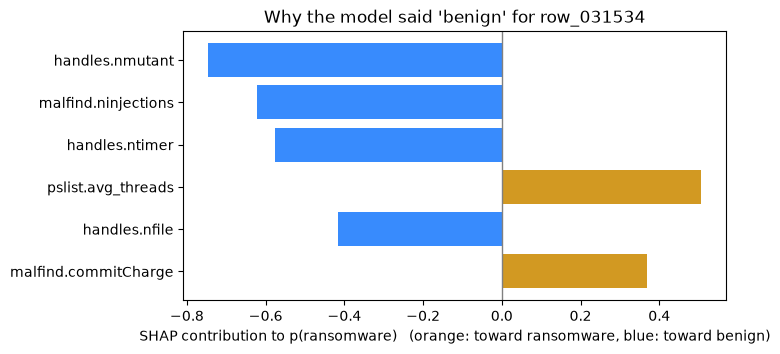

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
names = [f["name"] for f in ev["top_features"]][::-1]
val = [f["shap"] for f in ev["top_features"]][::-1]
colors = ["#d29922" if v > 0 else "#388bfd" for v in val]
ax.barh(names, val, color=colors)
ax.axvline(0, color="grey", linewidth=1)
ax.set_xlabel("SHAP contribution to p(ransomware)   (orange: toward ransomware, blue: toward benign)")
ax.set_title(f"Why the model said '{ev['verdict']}' for {SAMPLE_UID}")
fig.savefig(Paths.figs / "notebook02_shap.png", dpi=110, bbox_inches="tight")
plt.show()


## 3. Explain the verdict with the template

`template_rationale()` writes the deterministic explanation used as arm `T` in the
study: one sentence per evidence row, no invention possible. It is the sanity ceiling
for faithfulness — if this does not score 1.0, the verifier is broken.


In [6]:
template = template_rationale(ev)
print(template["summary"])
score = score_rationale(template, ev, VALUE_TOL, PROB_TOL)
print(f"\nFS = {score['FS']:.3f}   pass = {score['FS_pass']}   claims = {score['n_claims']}   "
      f"coverage = {score['evidence_coverage']:.2f}")
pd.DataFrame(score["per_claim"])[["feature", "status", "failed_checks", "stated_value",
                                 "evidence_value"]]


The classifier predicts benign with probability 0.054. handles.nmutant is typical compared with training data (value 282.0, 48th percentile), which pushed the decision toward benign. malfind.ninjections is very_high compared with training data (value 78.0, 99th percentile), which pushed the decision toward benign. handles.ntimer is typical compared with training data (value 129.0, 48th percentile), which pushed the decision toward benign. pslist.avg_threads is very_low compared with training data (value 7.55, 1th percentile), which pushed the decision toward ransomware. handles.nfile is typical compared with training data (value 681.0, 44th percentile), which pushed the decision toward benign. malfind.commitCharge is very_high compared with training data (value 9,215, 95th percentile), which pushed the decision toward ransomware.

FS = 1.000   pass = True   claims = 6   coverage = 1.00


,feature,status,failed_checks,stated_value,evidence_value
0,handles.nmutant,supported,[],282.000000,282.000000
1,malfind.ninjections,supported,[],78.000000,78.000000
2,handles.ntimer,supported,[],129.000000,129.000000
3,pslist.avg_threads,supported,[],7.548387,7.548387
4,handles.nfile,supported,[],681.000000,681.000000
5,malfind.commitCharge,supported,[],9215.000000,9215.000000


## 4. Catch an explanation that lies

Here is the point of the whole project. Below are four explanations of the *same*
verdict. Three of them contain a specific, realistic error — the kind an LLM makes:

* **flipped direction** — a feature that pushed toward ransomware is claimed to have
  pushed toward benign;
* **wrong value** — the number quoted is not the evidence value;
* **invented feature** — it talks about a feature that is not in the evidence list.

The checker is deterministic Python: it extracts the claims (offline rules, no model
needed) and verifies each one against the evidence table. Note that the plain-language
verdict is right in all four — only the claim-level check exposes the lies.


In [7]:
VERDICT_LINE = "The classifier predicts benign with probability 0.054. "

variants = {
    "A faithful (template)": template["summary"],
    "B flipped direction": VERDICT_LINE + (
        "malfind.commitCharge is very_high compared with training data (value 9,215), "
        "which pushed the decision toward benign."),
    "C wrong value": VERDICT_LINE + (
        "handles.nmutant is typical compared with training data (value 999.0), "
        "which pushed the decision toward benign."),
    "D invented feature": VERDICT_LINE + (
        "svcscan.nservices is very_high compared with training data (value 500.0), "
        "which pushed the decision toward ransomware."),
}

rows = []
for name, prose in variants.items():
    claims = extract_claims(prose, features)
    verdict, prob = infer_verdict_and_probability(prose)
    s = score_rationale({"verdict": verdict, "probability_stated": prob,
                         "claims": claims, "summary": prose}, ev, VALUE_TOL, PROB_TOL)
    problems = [f"{c['feature']} [{','.join(c['failed_checks'])}]"
                for c in s["per_claim"] if c["status"] != "supported"]
    rows.append({"explanation": name, "verdict_ok": s["verdict_ok"], "claims": s["n_claims"],
                 "FS": round(s["FS"], 3), "faithful": s["FS_pass"],
                 "caught": "; ".join(problems) or "-"})

variants_table = pd.DataFrame(rows)
print(variants_table.to_string(index=False))
variants_table


          explanation  verdict_ok  claims  FS  faithful                              caught
A faithful (template)        True       6 1.0      True                                   -
  B flipped direction        True       1 0.0     False malfind.commitCharge [direction_ok]
        C wrong value        True       1 0.0     False          handles.nmutant [value_ok]
   D invented feature        True       1 0.0     False  svcscan.nservices [feature_exists]


,explanation,verdict_ok,claims,FS,faithful,caught
0,A faithful (template),True,6,1.0,True,-
1,B flipped direction,True,1,0.0,False,malfind.commitCharge [direction_ok]
2,C wrong value,True,1,0.0,False,handles.nmutant [value_ok]
3,D invented feature,True,1,0.0,False,svcscan.nservices [feature_exists]


Read that table as a triage rule of thumb:

* `verdict_ok` only tells you the model said the right thing about *itself*.
* `FS` and the `caught` column tell you whether the *content* matches the evidence.
* B/C/D all have `verdict_ok = True` and `faithful = False`: the explanation sounds
  right, cites real-sounding numbers, and is still not trustworthy.


## 5. Use a real LLM instead of the template

Everything above works with a model-written explanation too — the verifier does not
care who wrote the text. Pick a backend in `.env` (`LLM_BACKEND`) and run the same
sample through the CLI, which does steps 1–5 for you:

```bash
# 1) local Ollama (no key, nothing leaves the machine)
echo 'LLM_BACKEND=ollama' >> .env && echo 'LLM_MODEL=llama3.2:3b' >> .env
python -m src.cli check --sample test_003028 --explain llm

# 2) any OpenAI-compatible endpoint (OpenRouter, Groq, vLLM, llama-server, ...)
#    LLM_BASE_URL=https://openrouter.ai/api/v1  LLM_API_KEY=...  LLM_MODEL=<model id>
python -m src.cli check --sample test_003028 --explain llm --mode structured

# 3) the agent queue (no key at all: prompts wait in queue/ for the coding agent)
python -m src.cli check --sample test_003028 --explain llm --repair 2
```

`--repair N` is the loop from RQ2: score the explanation, turn every failed claim into
a short correction list, ask again, re-score. In the study it lifted mean FS from
0.772 to 0.891 on zero-shot prose (22/50 samples fixed).


In [8]:
record = {
    "sample_id": SAMPLE_UID,
    "verdict": ev["verdict"],
    "probability_ransomware": round(p, 6),
    "top_features": ev["top_features"],
    "explanation": {"mode": "template", "text": template["summary"]},
    "faithfulness": {"FS": score["FS"], "FS_pass": score["FS_pass"],
                     "claim_precision": score["claim_precision"],
                     "status_counts": score["status_counts"]},
}
out = Paths.outputs / "triage_notebook_example.json"
out.write_text(json.dumps(record, indent=2))
print("wrote", out)
print(json.dumps({k: record[k] for k in ("sample_id", "verdict", "probability_ransomware",
                                        "faithfulness")}, indent=2))


wrote /home/faddy/Desktop/githubrepos/ransomware-rationale/outputs/triage_notebook_example.json
{
  "sample_id": "row_031534",
  "verdict": "benign",
  "probability_ransomware": 0.054099,
  "faithfulness": {
    "FS": 1.0,
    "FS_pass": true,
    "claim_precision": 1.0,
    "status_counts": {
      "supported": 6,
      "unsupported": 0,
      "contradicted": 0
    }
  }
}


## 6. Where to go next

| I want to … | do this |
|---|---|
| check one sample | `python -m src.cli check --sample test_003028` |
| check a sample I have as a CSV row | `python -m src.cli template --out my_sample.csv` then `check --csv` |
| triage a whole CSV | `python -m src.cli batch --csv data/raw/CIC-MalMem-2022.csv --stride 1500 --limit 30` |
| call it from a program / agent | `python -m src.cli check ... --json` (one JSON object on stdout) |
| see how the classifier was trained | `notebooks/01_train_the_classifier.ipynb` |
| see the full study | `make all` → `outputs/report.md` |

Reminder from section 3 of notebook 1: this model separates **ransomware from
everything else**. A "benign" verdict means "not ransomware", never "clean".
